### Taxi Problem using Q-Learning

In [23]:
%pip install --upgrade gymnasium typing_extensions
import gymnasium as gym
import numpy as np 
import matplotlib.pyplot as plt

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.0 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [24]:
# Configure the Taxi-v3 environment
env =gym.make("Taxi-v4")

print("Number of states:", env.observation_space.n)
print("Number of actions:", env.action_space.n)

Number of states: 500
Number of actions: 6


The Taxi environment has 500 states and 6 possible actions. The taxi must navigate the grid, pick up a passenger, and drop them at the correct destination.

In [25]:
# Initialize Q-table and parameters
q_table = np.zeros((env.observation_space.n, env.action_space.n))
learning_rate = 0.7
discount_factor = 0.95
epsilon = 1.0
epsilon_min=0.05
epsilon_decay=0.995

episodes=10000
max_steps=200

episode_rewards = []
episode_steps = []
success_history = []

In [26]:
for episode in range(episodes):
    state, info = env.reset()

    total_reward = 0
    steps = 0
    success = 0

    for step in range(max_steps):

        # Choose an action using epsilon-greedy strategy
        if np.random.random() < epsilon:
            action = env.action_space.sample()
        else:
            action = np.argmax(q_table[state])

        # Perform the action
        next_state, reward, terminated, truncated, info = env.step(action)

        # Update Q-value using the Q-learning formula
        best_next_value = np.max(q_table[next_state])

        q_table[state, action] += learning_rate * (
            reward
            + discount_factor * best_next_value
            - q_table[state, action]
        )

        state = next_state
        total_reward += reward
        steps = step + 1

        if terminated:
            success = 1
            break

        if truncated:
            break

    # Gradually reduce exploration
    epsilon = max(epsilon_min, epsilon * epsilon_decay)

    episode_rewards.append(total_reward)
    episode_steps.append(steps)
    success_history.append(success)

env.close()

print("Training completed!")

Training completed!


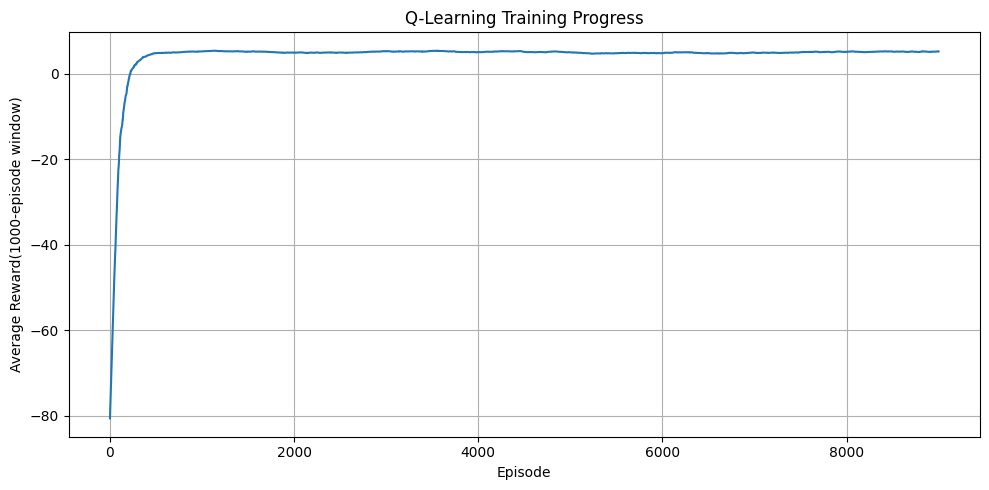

In [27]:
# Plot the training rewards
window=1000

average_rewards = np.convolve(episode_rewards,np.ones(window)/window,mode="valid")

plt.figure(figsize=(10, 5))
plt.plot(average_rewards)

plt.title("Q-Learning Training Progress")
plt.xlabel("Episode")
plt.ylabel("Average Reward(1000-episode window)")
plt.grid(True)
plt.tight_layout()
plt.show()

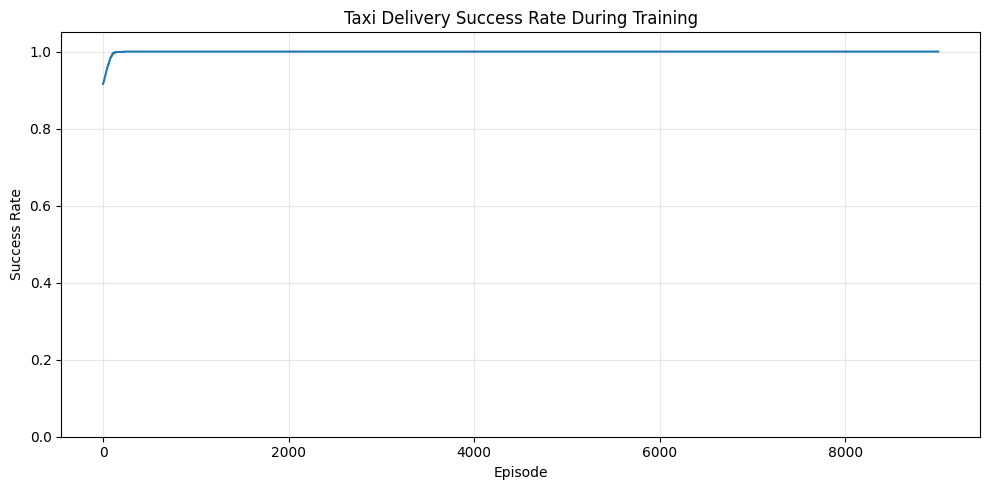

In [28]:
# Success rate during training
success_rate = np.convolve(success_history, np.ones(window)/window, mode='valid')

plt.figure(figsize=(10, 5))
plt.plot(success_rate)

plt.title("Taxi Delivery Success Rate During Training")
plt.xlabel("Episode")
plt.ylabel("Success Rate")
plt.ylim(0, 1.05)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [29]:
# Evaluate the trained agent
test_episodes = 100
test_rewards = []
test_steps = []
successes=0

for episode in range(test_episodes):
    state, info = env.reset()
    total_reward = 0

    for step in range(max_steps):
        # Choose the best learned action
        action = int(np.argmax(q_table[state]))

        state, reward, terminated, truncated, info = env.step(action)
        total_reward += reward

        if terminated:
            successes += 1
            break

        if truncated:
            break

    test_rewards.append(total_reward)
    test_steps.append(step + 1)

print("Evaluation results")
print("------------------")
print("Average reward:", round(np.mean(test_rewards), 2))
print("Average steps:", round(np.mean(test_steps), 2))
print("Successful deliveries:", successes, "/", test_episodes)
print("Success rate:", round(successes / test_episodes * 100, 2), "%")

env.close()

Evaluation results
------------------
Average reward: 8.24
Average steps: 12.76
Successful deliveries: 100 / 100
Success rate: 100.0 %


In [30]:
demo_env = gym.make("Taxi-v4", render_mode="ansi")
state, info = demo_env.reset(seed=7)

total_reward = 0

print("Initial environment:")
print(demo_env.render())

for step in range(max_steps):
    action = int(np.argmax(q_table[state]))

    state, reward, terminated, truncated, info = demo_env.step(action)
    total_reward += reward

    print(f"Step {step + 1} | Action: {action} | Reward: {reward}")
    print(demo_env.render())

    if terminated:
        print("Passenger delivered successfully!")
        break

    if truncated:
        print("Step limit reached.")
        break

print("Total demonstration reward:", total_reward)

demo_env.close()

Initial environment:
+---------+
|R: | : :G|
| : | : : |
| : : : : |
| | : | : |
|Y| : |B: |
+---------+


Step 1 | Action: 0 | Reward: -1
+---------+
|R: | : :G|
| : | : : |
| : : : : |
| | : | : |
|Y| : |B: |
+---------+
  (South)

Step 2 | Action: 4 | Reward: -1
+---------+
|R: | : :G|
| : | : : |
| : : : : |
| | : | : |
|Y| : |B: |
+---------+
  (Pickup)

Step 3 | Action: 1 | Reward: -1
+---------+
|R: | : :G|
| : | : : |
| : : : : |
|_| : | : |
|Y| : |B: |
+---------+
  (North)

Step 4 | Action: 1 | Reward: -1
+---------+
|R: | : :G|
| : | : : |
|_: : : : |
| | : | : |
|Y| : |B: |
+---------+
  (North)

Step 5 | Action: 2 | Reward: -1
+---------+
|R: | : :G|
| : | : : |
| :_: : : |
| | : | : |
|Y| : |B: |
+---------+
  (East)

Step 6 | Action: 2 | Reward: -1
+---------+
|R: | : :G|
| : | : : |
| : :_: : |
| | : | : |
|Y| : |B: |
+---------+
  (East)

Step 7 | Action: 2 | Reward: -1
+---------+
|R: | : :G|
| : | : : |
| : : :_: |
| | : | : |
|Y| : |B: |
+---------+
  (East)

Step 8

### Q-Learning Formula:
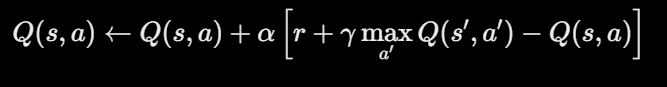